<a href="https://colab.research.google.com/github/zerogradlabs/zerograd-python/blob/main/examples/titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ZeroGrad on Titanic: check every number yourself

Predict who survived the Titanic **without training a model**. ZeroGrad compares pretrained tabular foundation models on your labeled history, keeps the best one (the *champion*) and scores new rows with it.

Everything here runs on your machine (or this Colab), with no account and no API key. We keep our own holdout aside, so at the end we check ZeroGrad's numbers ourselves.

In [1]:
!pip install -q zerograd

## 1. Data

The OpenML version of Titanic has 1,309 passengers. We keep 20% aside as our own holdout: no model ever sees it.

`boat` and `body` are only known *after* the sinking (who got on a lifeboat, whose body was found), so they would leak the answer. `home.dest` is free text. We drop the three.

In [2]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

df = fetch_openml("titanic", version=1, as_frame=True).frame
df = df.drop(columns=["boat", "body", "home.dest"])
train, holdout = train_test_split(df, test_size=0.2, stratify=df["survived"], random_state=0)
len(train), len(holdout)

(1047, 262)

## 2. The championship

One call. ZeroGrad profiles the columns (drops identifiers and free text such as `name` and `ticket`), holds out 20% of `train`, scores **every** holdout row with each model and keeps the best. The first run downloads each model's weights from its official repository (once).

In [3]:
from zerograd import ZeroGrad

zg = ZeroGrad()   # local: no API key
cap = zg.create("titanic-survival", examples=train, target="survived")
cap.evaluation

/home/runner/work/zerograd-python/zerograd-python/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
◆ ZeroGrad 0.2.3 · local · 2 models ready: TabPFN v2, TabICLv2


  Hold on tight, going gradless.


✓ 1,047 labeled rows · 7 columns used · dropped name, ticket, cabin


◆ Championship · 2 models · Let them read the room.


✓ Context 838 rows · holdout 209 rows (every row scored)


… TabPFN v2 (1 of 2)


... (5 outputs left out)

     without a model  0.500  (ROC AUC, majority class)


◆ Champion: TabICLv2 · ROC AUC 0.853


  No GPUs were overworked in the making of this model.


,roc_auc,pr_auc,log_loss,accuracy,balanced_accuracy,f1,precision,recall,seconds,champion
model,,,,,,,,,,
TabPFN v2,0.850630,0.756363,0.473242,0.794258,0.764486,0.703448,0.784615,0.6375,13.54,False
TabICLv2,0.852859,0.773504,0.468090,0.789474,0.774855,0.721519,0.730769,0.7125,6.55,True


In [4]:
cap.baselines   # the same holdout without a model: random scores and always the majority class

,roc_auc,accuracy,log_loss
baseline,,,
Coin flip (random scores),0.459399,0.473684,1.113989
Always the most common class,0.500000,0.617225,0.665408


In [5]:
cap.columns     # which columns were used, and why the others were dropped

{'used': [{'name': 'pclass', 'kind': 'numeric'},
  {'name': 'sex', 'kind': 'categorical'},
  {'name': 'age', 'kind': 'numeric'},
  {'name': 'sibsp', 'kind': 'numeric'},
  {'name': 'parch', 'kind': 'numeric'},
  {'name': 'fare', 'kind': 'numeric'},
  {'name': 'embarked', 'kind': 'categorical'}],
 'dropped': [{'name': 'name', 'reason': 'free text or high-cardinality id'},
  {'name': 'ticket', 'reason': 'free text or high-cardinality id'},
  {'name': 'cabin', 'reason': 'free text or high-cardinality id'}]}

## 3. Predict our own holdout and check the numbers

In [6]:
from sklearn.metrics import accuracy_score, roc_auc_score

preds = cap.predict(holdout.drop(columns="survived"))
y = holdout["survived"].astype(int)
print("ROC AUC ", round(roc_auc_score(y, preds["score"]), 3))
print("Accuracy", round(accuracy_score(y, preds["prediction"].astype(int)), 3))
preds.head()

… Warming up TabICLv2 with 1,047 rows of context · Reading your history. Not training on it.


✓ TabICLv2 ready 7.1s


ROC AUC  0.893
Accuracy 0.832


,prediction,score,proba_0,proba_1
544,0,0.081091,0.918909,0.081091
599,1,0.808303,0.191697,0.808303
803,0,0.103157,0.896843,0.103157
1065,0,0.313543,0.686457,0.313543
454,0,0.040780,0.959220,0.040780


In [7]:
# One passenger, as an app would call it: a dict in, a dict out
passenger = holdout.drop(columns="survived").iloc[0].to_dict()
cap.predict(passenger)

{'prediction': '0',
 'score': 0.08109128475189209,
 'proba': {'0': 0.9189087152481079, '1': 0.08109128475189209}}

## 4. How much history do you need?

Foundation models read their context (the labeled rows) on every prediction, so a smaller context answers faster. `context_curve` runs the champion on growing samples of its own context and scores each on our holdout. The recommended size is the smallest one within 0.005 of the best ROC AUC.

In [8]:
curve = cap.context_curve(holdout, sizes=[50, 100, 200, 400, 800])
curve

◆ Context curve · TabICLv2 · 5 sizes · 262 test rows


… 50 rows of context


✓ 50 rows · ROC AUC 0.776 · 1.6s


… 100 rows of context


✓ 100 rows · ROC AUC 0.855 · 1.8s


… 200 rows of context


... (3 outputs left out)

… 800 rows of context


✓ 800 rows · ROC AUC 0.890 · 7.2s


  → 800 rows of context score best (ROC AUC 0.890).


,roc_auc,fit_seconds,predict_seconds,ms_per_row,recommended
rows,,,,,
50,0.776,0.28,1.28,4.87,False
100,0.855,0.28,1.53,5.85,False
200,0.860,0.28,2.04,7.79,False
400,0.871,0.29,3.45,13.16,False
800,0.890,0.28,6.91,26.39,True


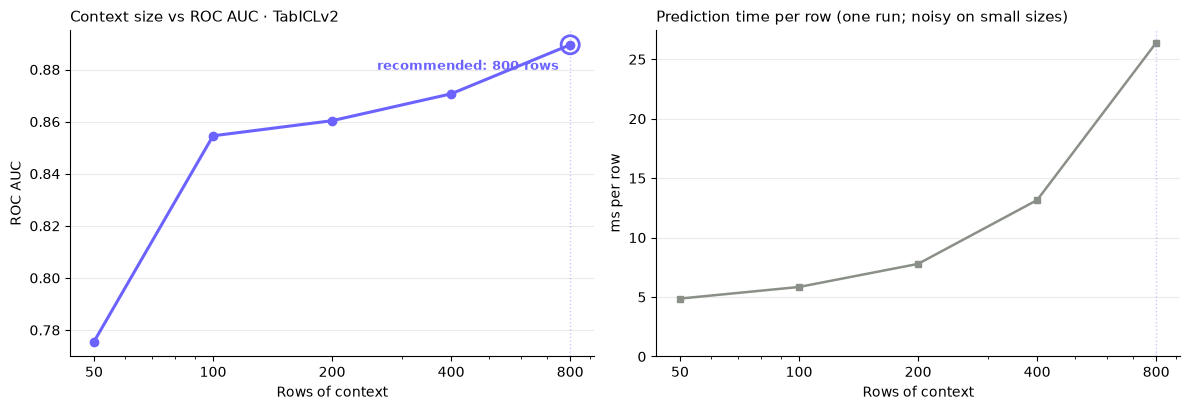

In [9]:
curve.plot();

In [10]:
cap.update(context_rows=curve.recommended)   # predict with the smaller, faster context from now on
len(cap.context_y)

800

## 5. Multiclass: Iris

The same calls work for three classes.

In [11]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True).frame
iris_cap = zg.create("iris", examples=iris.sample(120, random_state=0), target="target")
iris_cap.predict(iris.drop(columns="target").tail(3))

✓ 120 labeled rows · 4 columns used


◆ Championship · 2 models · May the best prior win.


✓ Context 96 rows · holdout 24 rows (every row scored)


… TabPFN v2 (1 of 2)


✓ TabPFN v2 (1 of 2) 0.8s


… TabICLv2 (2 of 2)


... (5 outputs left out)

  No GPUs were overworked in the making of this model.


… Warming up TabPFN v2 with 120 rows of context · Reading your history. Not training on it.


✓ TabPFN v2 ready 0.7s


,prediction,proba_0,proba_1,proba_2
147,2,2.649155e-07,0.000899,0.999101
148,2,3.176933e-07,0.000126,0.999874
149,2,8.559209e-07,0.016274,0.983725


## 6. Keep it, or run it in production

`cap.save("titanic.zg")` writes the capability to one file (no weights inside) and `zerograd.load` opens it anywhere the SDK is installed. The file holds a sample of your rows as the model's context: treat it like the data.

To run it in production with versions, scheduled championships, monitoring and Explain, the same code runs on the ZeroGrad platform with `ZeroGrad(remote=True)`: see [zerograd.dev](https://zerograd.dev).

In [12]:
cap.save("titanic.zg")

PosixPath('titanic.zg')